# EDA 

In [2]:
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt
import re
import geopandas as gpd
from geopy.geocoders import Nominatim
from geopy.extra.rate_limiter import RateLimiter
import folium

In [3]:
DATA_DIR = Path("../data")

In [4]:
dem_df = pd.read_csv(f"{DATA_DIR}/Zbiorcze statystyki demograficzne dla Krakowa, od 1995 roku.csv", sep=";")

# Dane demograficzne

In [5]:
display(dem_df.head())

,Lp,Rok,Liczba ludności ogółem,Liczba kobiet,Liczba mężczyzn,Liczba kobiet na 100 mężczyzn,Liczba osób w wieku przedprodukcyjnym,Liczba osób w wieku produkcyjnym,Liczba osób w wieku poprodukcyjnym,Urodzenia,Zgony,Przyrost naturalny (w osobach),Przyrost naturalny na 1 tysiąc ludności,Saldo migracji,Saldo migracji wewnętrznej,Saldo migracji zagranicznych,Małżeństwa,Rozwody
0,1,1995,744987,394583,350404,113,167622,465878,111487,6258,7277,-1019,-1.40,583,661,-78,3734.0,903.0
1,2,1996,740675,393262,347413,113,162716,463887,114072,6274,7171,-879,-1.30,1489,1574,-85,3535.0,925.0
2,3,1997,740537,392822,347715,113,157013,467256,116268,6040,7310,-1270,-1.80,277,206,71,3443.0,1051.0
3,4,1998,740666,393070,347596,113,152019,470470,118177,6054,6985,-931,-1.30,503,478,25,3592.0,1128.0
4,5,1999,755355,400804,354551,113,150226,484356,120773,5840,7075,-1235,-1.73,489,623,-134,4202.0,1147.0


In [8]:
print(f"Kolumny danych demograficznych: {list(dem_df.columns)}")

Kolumny danych demograficznych: ['Lp', 'Rok', 'Liczba ludności ogółem ', 'Liczba kobiet ', 'Liczba mężczyzn', 'Liczba kobiet na 100 mężczyzn', 'Liczba osób w wieku przedprodukcyjnym', 'Liczba osób w wieku produkcyjnym ', 'Liczba osób w wieku  poprodukcyjnym ', 'Urodzenia ', 'Zgony ', 'Przyrost naturalny (w osobach)', 'Przyrost naturalny na 1 tysiąc ludności ', 'Saldo migracji ', 'Saldo migracji wewnętrznej ', 'Saldo migracji zagranicznych', 'Małżeństwa ', 'Rozwody']


In [11]:
dem_df.isna().sum()[dem_df.isna().sum() > 0]

Małżeństwa     1
Rozwody        1
dtype: int64

In [12]:
dem_df.loc[20, :]

Lp                                              21.00
Rok                                           2015.00
Liczba ludności ogółem                      761069.00
Liczba kobiet                               406115.00
Liczba mężczyzn                             354954.00
Liczba kobiet na 100 mężczyzn                  114.00
Liczba osób w wieku przedprodukcyjnym       120953.00
Liczba osób w wieku produkcyjnym            471743.00
Liczba osób w wieku  poprodukcyjnym         168373.00
Urodzenia                                     8013.00
Zgony                                         7598.00
Przyrost naturalny (w osobach)                 415.00
Przyrost naturalny na 1 tysiąc ludności          0.54
Saldo migracji                                1840.00
Saldo migracji wewnętrznej                    3766.00
Saldo migracji zagranicznych                  1543.00
Małżeństwa                                        NaN
Rozwody                                           NaN
Name: 20, dtype: float64

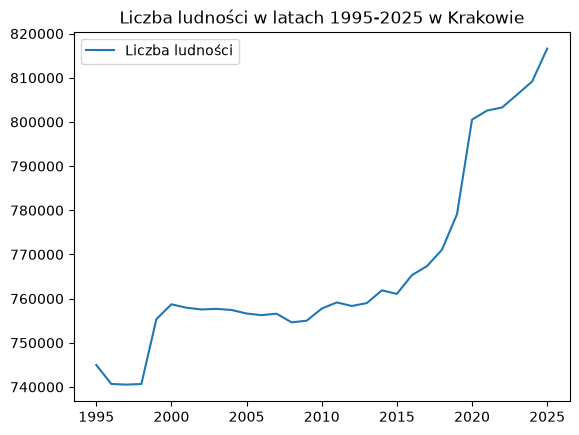

In [15]:
plt.plot(dem_df["Rok"], dem_df["Liczba ludności ogółem "])
plt.legend(['Liczba ludności'])
plt.title("Liczba ludności w latach 1995-2025 w Krakowie");

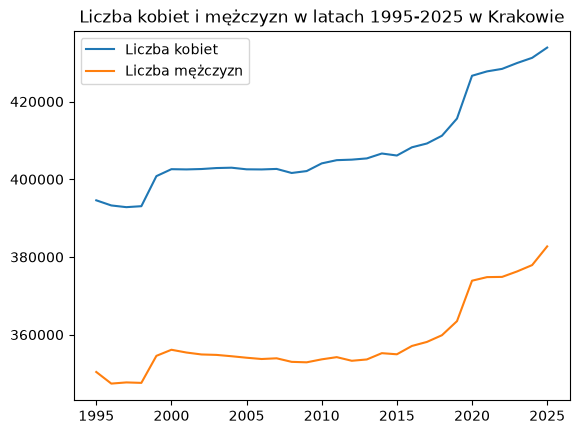

In [14]:
plt.plot(dem_df["Rok"], dem_df["Liczba kobiet "])
plt.plot(dem_df["Rok"], dem_df["Liczba mężczyzn"])
plt.legend(['Liczba kobiet', 'Liczba mężczyzn'])
plt.title("Liczba kobiet i mężczyzn w latach 1995-2025 w Krakowie");

### Wnioski:
W danych są tylko dwie brakujące wartości w 2015 saldo migracji i saldo migracji zagranicznych. Warto zwrócić uwagę na to, że nazwy kolumn mają spacje na końcu, na co trzeba uważać biorąc konkretne nazwy. 
### Możliwy sposób wykorzystania: 
Statyczna strona wyświetlająca statystyki (MVP), dynamiczna strona, która pozwala użytkownikowi eksplorować dane wybierając zakres dat oraz konkretne statystyki. Strona może oferować kilka podstawowych opcji (np. Liczba mężczyzn vs Liczba kobiet), ale powinna dawać użytkownikowi całkowitą swobodę, co wzmacnia ciekawość.

# Przedszkola

In [10]:
przedszkola_pattern = r"^Przedszkola\s+(?:nie)?samorządowe\s+w\s+roku\s+(\d+-\d+)"

In [11]:
all_przed_df = []

for file_path in DATA_DIR.glob("*"):
    if file_path.is_file():
        match = re.search(przedszkola_pattern, file_path.name)
        if match:
            years = match.group(1)
            df = pd.read_csv(file_path, sep=";")
            df["years"] = years
            all_przed_df.append(df)

In [12]:
all_przed_df = pd.concat(all_przed_df, ignore_index=True)

In [13]:
print(all_przed_df.columns)

Index(['Lp', 'Numer RSPO', 'Typ szkoły_placówki', 'Nazwa szkoły_placówki',
       'Liczba uczniów ogółem', 'Liczba oddziałów ogółem',
       'Typ organu prowadzącego', 'Organ prowadzący', 'Wojewodztwo', 'Powiat',
       'Gmina', 'Miejscowość', 'Ulica', 'Nr domu', 'Nr lokalu', 'Kod pocztowy',
       'Poczta', 'Specyfika szkoły', 'Telefon', 'Kategoria uczniów',
       'Publiczność szkoły_placówki ', 'years', 'Liczba dzieci ogółem',
       'Publiczność szkoły_placówki', 'Województwo'],
      dtype='str')


In [14]:
all_przed_df.isna().sum()

Lp                                0
Numer RSPO                        0
Typ szkoły_placówki               0
Nazwa szkoły_placówki             0
Liczba uczniów ogółem           638
Liczba oddziałów ogółem          31
Typ organu prowadzącego         621
Organ prowadzący                349
Wojewodztwo                     272
Powiat                          621
Gmina                           621
Miejscowość                       0
Ulica                             0
Nr domu                          11
Nr lokalu                       903
Kod pocztowy                      0
Poczta                          756
Specyfika szkoły                 16
Telefon                         349
Kategoria uczniów               621
Publiczność szkoły_placówki     621
years                             0
Liczba dzieci ogółem            488
Publiczność szkoły_placówki     473
Województwo                     822
dtype: int64

### Brakujące dane
Kolumny 'Liczba uczniów ogółem' i 'Liczba dzieci ogółem' to dwie kolumny opisujące to samo zjawisko, więc można ją połączyć. Jeżeli chodzi o pozostałe braki w danych to nie dotyczą one kolumn, które nas interesują tj. Miejscowość, Ulica, Nr domu i Kod pocztowy, które pomogą nam zlokalizować współrzędne obiektów.

In [15]:
unique_przed_df = all_przed_df[['Nazwa szkoły_placówki', 'Miejscowość', 'Ulica', 'Nr domu', 'Kod pocztowy']].copy()
unique_przed_df = unique_przed_df.drop_duplicates().reset_index()

unique_przed_df["adres"] = (
    unique_przed_df["Ulica"].fillna("").astype(str)
    + " "
    + unique_przed_df["Nr domu"].fillna("").astype(str)
    + ", "
    + unique_przed_df["Kod pocztowy"].fillna("").astype(str)
).str.strip()

unique_przed_df = unique_przed_df.drop(['Miejscowość', 'Ulica', 'Nr domu', 'Kod pocztowy'], axis=1)

In [24]:
display(unique_przed_df)

NameError: name 'unique_przed_df' is not defined

### Geokodowanie
Używamy biblioteki geopy i silnika Nominatim, który korzysta z otwartych danych projektu OpenStreetMap. Celem geokodowania jest dodanie współrzędnych do danych, które posiadają jedynie adres.

In [23]:
MIASTO = "Kraków"
KRAJ = "Polska"

geolocator = Nominatim(
    user_agent="city_infrastructure_student_prototype"
)

geocode = RateLimiter(
    geolocator.geocode,
    min_delay_seconds=1.1,
    max_retries=2,
    error_wait_seconds=5,
    swallow_exceptions=True,
)

for i, row in unique_przed_df.iterrows():

    address = str(row["adres"]).strip()
    if not address or address.lower() == "nan":
        continue

    query = f"{address}, {MIASTO}, {KRAJ}"
    location = geocode(query, country_codes="pl", language="pl")

    if location:
        unique_przed_df.at[i, "latitude"] = location.latitude
        unique_przed_df.at[i, "longitude"] = location.longitude
        df.at[i, "matched_address"] = location.address

In [25]:
display(unique_przed_df.head())

,index,Nazwa szkoły_placówki,adres,latitude,longitude
0,0,NIEPUBLICZNY PUNKT PRZEDSZKOLNY WESOŁY ZAKĄTEK,"Pod Fortem 2, 31-302",50.082412,19.922246
1,1,NIEPUBLICZNY PUNKT PRZEDSZKOLNY PANDA,"Leona Petrażyckiego 52, 30-399",49.983619,19.888956
2,2,"NIEPUBLICZNE PRZEDSZKOLE ""JARZĘBINKA"" Z ODDZIA...","Starowiejska 36, 30-698",49.987442,19.929808
3,3,NIEPUBLICZNE PRZEDSZKOLE ARCELORMITTAL POLAND ...,"Osiedle Centrum A 14, 31-925",50.072268,20.040633
4,4,"NIEPUBLICZNE PRZEDSZKOLE ""MUSZELKA"" Z ODDZIAŁA...","Marii i Bolesława Wysłouchów 4, 30-611",50.007854,19.949746


In [27]:
unique_przed_df.to_csv(f"{DATA_DIR}/przedszkola_wspolrzedne.csv")

# Przystanki

In [20]:
przystanki = pd.read_csv(f"{DATA_DIR}/Przystanki_Komunikacji_Miejskiej_w_Krakowie.csv")

In [17]:
display(przystanki.head())

,OBJECTID,Kod BusMan,Nazwa przystanku z numerem,Typ przystanku,Rodzaj przystanku,Przystanek podwójny,Na żądanie,Geometria przystanku,Nawierzchnia miejsca zatrzymania,Nawierzchnia peronu,...,EditDate,Editor,Ramki rozkładowe,Obowiązuje od,Obowiązuje do,Strefa Biletowa,Ławki inne poza wiatą,Grupa,x,y
0,59,116-04,Gałczyńskiego 04,A,przelotowy,nie,nie,zatoka,beton,kostka,...,12/29/2025 10:17:57 AM,lodzinskij,0.0,NaN,NaN,I,0.0,KMK,2.227776e+06,6.458201e+06
1,94,448-03,Kuźnicy Kołłątajowskiej 03,A,przelotowy,nie,nie,jezdnia,asfalt,kostka,...,12/29/2025 10:17:58 AM,lodzinskij,1.0,NaN,NaN,I,0.0,KMK,2.221669e+06,6.463310e+06
2,95,448-04,Kuźnicy Kołłątajowskiej 04,A,przelotowy,nie,nie,jezdnia,asfalt,płyty_chodnikowe,...,12/29/2025 10:17:58 AM,lodzinskij,1.0,NaN,NaN,I,0.0,KMK,2.221804e+06,6.463343e+06
3,141,412-02,Pielęgniarek 02,A,przelotowy,nie,nie,zatoka,asfalt,kostka,...,7/30/2026 7:11:14 AM,lodzinskij,4.0,NaN,NaN,I,0.0,KMK,2.219350e+06,6.460743e+06
4,144,127-04,Morcinka 04,A,przelotowy,nie,tak,jezdnia,asfalt,asfalt,...,12/29/2025 10:17:59 AM,lodzinskij,0.0,NaN,NaN,I,0.0,KMK,2.234396e+06,6.464313e+06


In [18]:
print(przystanki.columns)

Index(['OBJECTID', 'Kod BusMan', 'Nazwa przystanku z numerem',
       'Typ przystanku', 'Rodzaj przystanku', 'Przystanek podwójny',
       'Na żądanie', 'Geometria przystanku',
       'Nawierzchnia miejsca zatrzymania', 'Nawierzchnia peronu',
       'Pasy medialne', 'Krawężnik peronu', 'Słupki liniowe',
       'Słupki dla innych przewoźników', 'Gabloty rozkładowe',
       'Gabloty dodatkowe', 'Gabloty na mapy', 'Ławki przystankowe poza wiatą',
       'Barierosiedziska', 'Kosze przystankowe', 'Kosze inne',
       'Inne konstrukcje', 'GlobalID', 'Wiaty przystankowe', 'EditDate',
       'Editor', 'Ramki rozkładowe', 'Obowiązuje od', 'Obowiązuje do',
       'Strefa Biletowa', 'Ławki inne poza wiatą', 'Grupa', 'x', 'y'],
      dtype='str')


In [23]:
print(f"Unikatowe typy przystanku: {list(przystanki['Typ przystanku'].unique())}")

Unikatowe typy przystanku: ['A', 'T', 'wA', 'TA', 'pA', 'pT', 'wT', 'tymA']


In [22]:
print(f"Unikatowe rodzaje przystanku: {list(przystanki['Rodzaj przystanku'].unique())}")

Unikatowe rodzaje przystanku: ['przelotowy', 'pętla', 'końcówka', 'dworzec', 'przelotowo-końcowy', nan]


In [30]:
print(przystanki['Na żądanie'].unique())

<ArrowStringArray>
['nie', 'tak', nan]
Length: 3, dtype: str


In [21]:
gdf = gpd.GeoDataFrame(
    przystanki,
    geometry=gpd.points_from_xy(przystanki["x"], przystanki["y"]),
    crs="EPSG:3857"
)

gdf.to_crs("EPSG:4326")
gdf["longitude"] = gdf.geometry.x
gdf["latitude"] = gdf.geometry.y

print(gdf[["x", "y", "longitude", "latitude"]].head())

              x             y     longitude      latitude
0  2.227776e+06  6.458201e+06  2.227776e+06  6.458201e+06
1  2.221669e+06  6.463310e+06  2.221669e+06  6.463310e+06
2  2.221804e+06  6.463343e+06  2.221804e+06  6.463343e+06
3  2.219350e+06  6.460743e+06  2.219350e+06  6.460743e+06
4  2.234396e+06  6.464313e+06  2.234396e+06  6.464313e+06
